<a href="https://colab.research.google.com/github/gayatrigbh02/CSL701-CE02-Machine-Learning-Lab/blob/main/Experiments%5CML_Experiment_10_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10


Student Name : Gayatri Ganpat Bhairavkar

Batch : CE1


Roll Number : CE02



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [ ]:

# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Upload Mall_Customers.csv in Google Colab
from google.colab import files
uploaded = files.upload()

# Load the dataset
df = pd.read_csv("Mall_Customers.csv")

# Display the first five rows
print("First five rows of the dataset:")
display(df.head())

# Check dataset information
print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())


Saving Mall_Customers.csv to Mall_Customers.csv
First five rows of the dataset:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset shape: (200, 5)

Column names: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [ ]:

# Select the two features for clustering
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].copy()

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original features:")
display(X.head())

print("\nStandardized features (first five rows):")
print(X_scaled[:5])

print("\nMean after scaling:", X_scaled.mean(axis=0).round(2))
print("Standard deviation:", X_scaled.std(axis=0).round(2))


Original features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Standardized features (first five rows):
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]

Mean after scaling: [-0. -0.]
Standard deviation: [1. 1.]


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

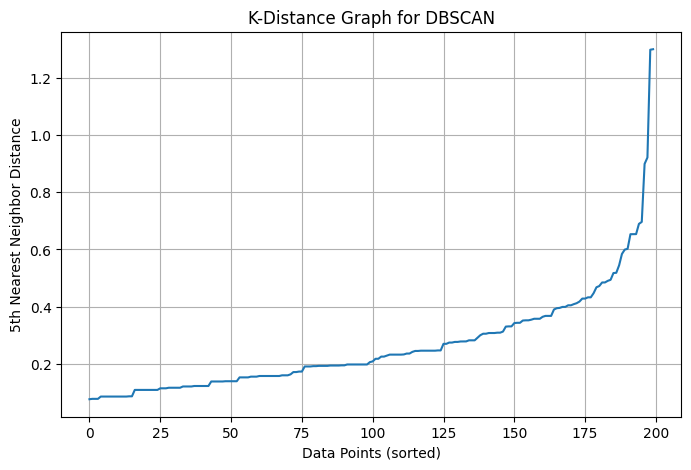

Selected min_samples: 5
Initial epsilon (eps): 0.35


In [ ]:

# Set min_samples
min_samples = 5

# Calculate distances to the 5th nearest neighbor
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Sort the distances
k_distances = np.sort(distances[:, min_samples - 1])

# Plot the k-distance graph
plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.xlabel("Data Points (sorted)")
plt.ylabel("5th Nearest Neighbor Distance")
plt.title("K-Distance Graph for DBSCAN")
plt.grid(True)
plt.show()

# Initial epsilon estimate; refine it by inspecting the elbow
eps = 0.35

print("Selected min_samples:", min_samples)
print("Initial epsilon (eps):", eps)


# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

First 10 customer cluster assignments:


,CustomerID,Annual Income (k$),Spending Score (1-100),Cluster
0,1,15,39,2
1,2,15,81,0
2,3,16,6,1
3,4,16,77,0
4,5,17,40,2
5,6,17,76,0
6,7,18,6,1
7,8,18,94,-1
8,9,19,3,1
9,10,19,72,0


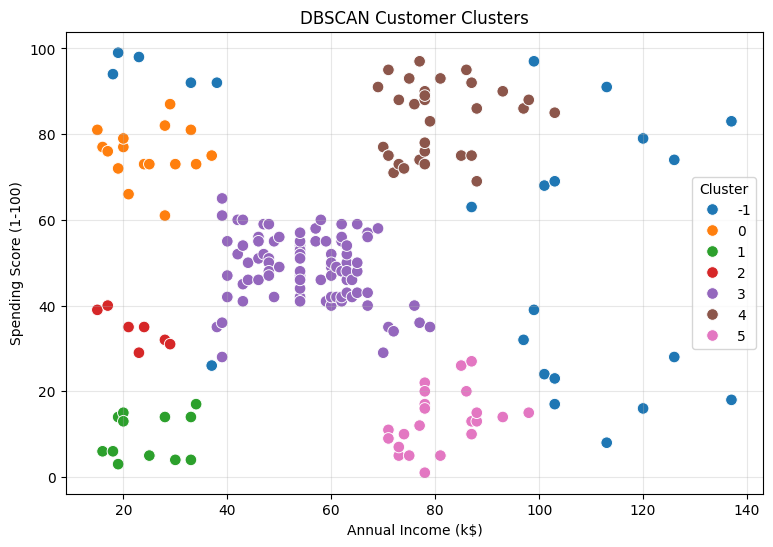

In [ ]:

# Create and train the DBSCAN model
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
df['Cluster'] = dbscan.fit_predict(X_scaled)

# Display cluster assignments
print("First 10 customer cluster assignments:")
display(df[['CustomerID'] + features + ['Cluster']].head(10))

# Plot the clusters
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='tab10',
    s=70
)

plt.title('DBSCAN Customer Clusters')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.grid(True, alpha=0.3)
plt.show()


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [ ]:

# Get cluster labels
labels = df['Cluster'].values

# Count clusters, excluding noise label -1
unique_labels = set(labels)
n_clusters = len(unique_labels - {-1})

# Count noise points
n_noise = np.sum(labels == -1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print("Percentage of noise points:",
      round((n_noise / len(df)) * 100, 2), "%")

# Calculate Silhouette Score, excluding noise points
non_noise = labels != -1
valid_labels = labels[non_noise]
valid_data = X_scaled[non_noise]

if len(set(valid_labels)) >= 2:
    score = silhouette_score(valid_data, valid_labels)
    print("Silhouette Score (excluding noise):", round(score, 4))
else:
    print("Silhouette Score cannot be calculated: "
          "fewer than two non-noise clusters.")

# Display the number of customers in each cluster
print("\nCustomers per cluster (-1 means noise):")
print(df['Cluster'].value_counts().sort_index())


Number of clusters: 6
Number of noise points: 23
Percentage of noise points: 11.5 %
Silhouette Score (excluding noise): 0.5577

Customers per cluster (-1 means noise):
Cluster
-1    23
 0    16
 1    12
 2     7
 3    88
 4    31
 5    23
Name: count, dtype: int64


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

Customer Cluster Statistics:


,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
-1,23,34.43,89.26,57.83
0,16,24.81,24.75,75.38
1,12,48.75,24.58,9.58
2,7,36.71,22.43,34.43
3,88,42.88,55.23,48.58
4,31,32.84,80.29,83.19
5,23,41.22,80.96,12.78


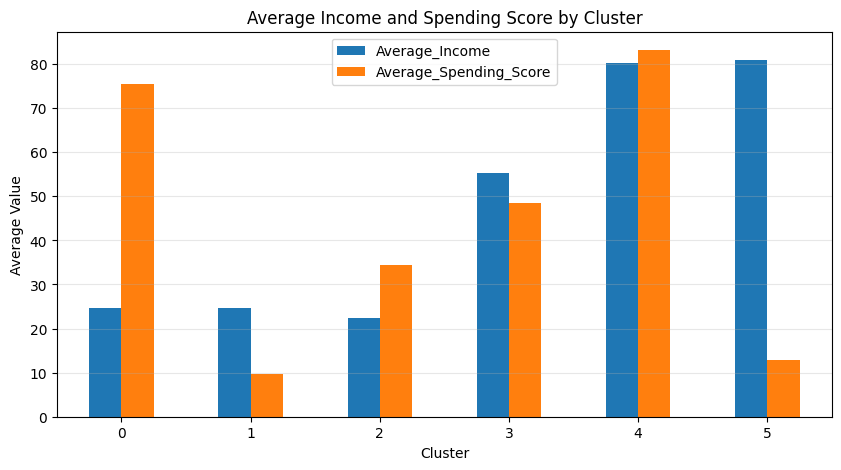


Number of noise customers: 23


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
7,8,Female,23,18,94,-1
11,12,Female,35,19,99,-1
19,20,Female,35,23,98,-1
33,34,Male,18,33,92,-1
38,39,Female,36,37,26,-1
41,42,Male,24,38,92,-1
169,170,Male,32,87,63,-1
180,181,Female,37,97,32,-1
184,185,Female,41,99,39,-1
185,186,Male,30,99,97,-1


In [ ]:

# Calculate statistics for each cluster, including noise
cluster_stats = df.groupby('Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Average_Age=('Age', 'mean'),
    Average_Income=('Annual Income (k$)', 'mean'),
    Average_Spending_Score=('Spending Score (1-100)', 'mean')
).round(2)

print("Customer Cluster Statistics:")
display(cluster_stats)

# Plot the average income and spending score by cluster
cluster_stats.drop(index=-1, errors='ignore')[
    ['Average_Income', 'Average_Spending_Score']
].plot(kind='bar', figsize=(10, 5))

plt.title('Average Income and Spending Score by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.show()

# Display noise customers separately
noise_customers = df[df['Cluster'] == -1]

print("\nNumber of noise customers:", len(noise_customers))
display(noise_customers.head(10))


# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.